<a href="https://colab.research.google.com/github/mdzubayereashraf/Ostad-AI-Engineering-Course-Assignments/blob/main/Assignmen_No_18(Sentiment_Analysis_on_Product_Reviews_(IMDB)_%7C%7C_Customer_Segmentation_Analysis).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Import Libraries and Load Dataset**

In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np

imdb = load_dataset("stanfordnlp/imdb")

print(imdb)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


## **Dataset Exploration (EDA)**

In [4]:
# Check dataset structure
print("Training samples:", len(imdb["train"]))
print("Testing samples:", len(imdb["test"]))

# Check sentiment labels
print("\nLabel distribution:")
print(pd.Series(imdb["train"]["label"]).value_counts())

# Display sentiment meaning
print("\nLabel meanings:")
print("0 = Negative")
print("1 = Positive")

Training samples: 25000
Testing samples: 25000

Label distribution:
0    12500
1    12500
Name: count, dtype: int64

Label meanings:
0 = Negative
1 = Positive


In [5]:
# Display a negative review
print("NEGATIVE REVIEW:\n")
print(imdb["train"][0]["text"])

print("\nSentiment:", imdb["train"][0]["label"])

# Display a positive review
print("\n" + "=" * 80)

print("\nPOSITIVE REVIEW:\n")
print(imdb["train"][1]["text"])

print("\nSentiment:", imdb["train"][1]["label"])

NEGATIVE REVIEW:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few an

## **Create a Cleaning Function**

In [6]:
import re
import string

def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

## **Test the Cleaning Function**

In [7]:
sample_review = imdb["train"][0]["text"]

cleaned_review = clean_text(sample_review)

print("Original Review:\n")
print(sample_review[:500])

print("\n" + "=" * 80)

print("\nCleaned Review:\n")
print(cleaned_review[:500])

Original Review:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent


Cleaned Review:

i rented i am curiousyellow from my video store because of all the controversy that surrounded it when it was first released in 1967 i also heard that at first it was seized by us customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants t

## **Prepare Training and Testing Data**

In [8]:
# Extract training data
X_train_text = imdb["train"]["text"]
y_train = np.array(imdb["train"]["label"])

# Extract testing data
X_test_text = imdb["test"]["text"]
y_test = np.array(imdb["test"]["label"])

# Apply text cleaning
X_train_clean = [clean_text(text) for text in X_train_text]
X_test_clean = [clean_text(text) for text in X_test_text]

print("Training reviews:", len(X_train_clean))
print("Testing reviews:", len(X_test_clean))

print("\nCleaned review example:")
print(X_train_clean[0][:300])

Training reviews: 25000
Testing reviews: 25000

Cleaned review example:
i rented i am curiousyellow from my video store because of all the controversy that surrounded it when it was first released in 1967 i also heard that at first it was seized by us customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to s


## **Train-Validation Split**

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train_split, y_val = train_test_split(
    X_train_clean,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test_clean))

Training samples: 20000
Validation samples: 5000
Testing samples: 25000


## **TF-IDF Vectorization**

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

## **Transform the Reviews**

In [11]:
# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test_clean)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (20000, 30000)
Validation TF-IDF shape: (5000, 30000)
Testing TF-IDF shape: (25000, 30000)


## **Train Logistic Regression Model**

In [12]:
from sklearn.linear_model import LogisticRegression

tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
tfidf_model.fit(X_train_tfidf, y_train_split)

print("TF-IDF Logistic Regression training completed!")

TF-IDF Logistic Regression training completed!


## **Calculate Evaluation Metrics**

In [13]:
# Predict validation data
y_val_pred = tfidf_model.predict(X_val_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate metrics
tfidf_accuracy = accuracy_score(y_val, y_val_pred)
tfidf_precision = precision_score(y_val, y_val_pred)
tfidf_recall = recall_score(y_val, y_val_pred)
tfidf_f1 = f1_score(y_val, y_val_pred)

print("TF-IDF Model - Validation Results")
print("-" * 40)

print(f"Accuracy:  {tfidf_accuracy:.4f}")
print(f"Precision: {tfidf_precision:.4f}")
print(f"Recall:    {tfidf_recall:.4f}")
print(f"F1-score:  {tfidf_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Negative", "Positive"]
))

TF-IDF Model - Validation Results
----------------------------------------
Accuracy:  0.8996
Precision: 0.8936
Recall:    0.9072
F1-score:  0.9004

Classification Report:

              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      2500
    Positive       0.89      0.91      0.90      2500

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



## **Confusion Matrix**

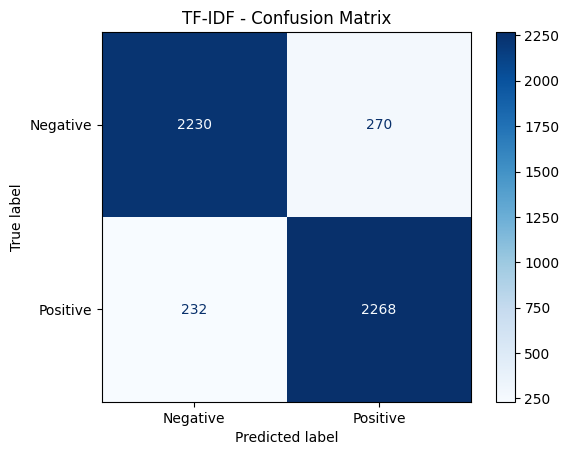

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("TF-IDF - Confusion Matrix")
plt.show()

## **Save the Results**

In [16]:
results = []

results.append({
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": tfidf_accuracy,
    "Precision": tfidf_precision,
    "Recall": tfidf_recall,
    "F1-score": tfidf_f1
})

pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1-score
0,TF-IDF + Logistic Regression,0.8996,0.893617,0.9072,0.900357
